<a href="https://colab.research.google.com/github/Geralf21/Analisis_Patrocinios_Clubes_Brasileros/blob/main/Analisis_Patrocinios_Clubes_Brasileros/NotebooksTP_pregunta_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [40]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


In [41]:
url = "https://raw.githubusercontent.com/Geralf21/Analisis_Patrocinios_Clubes_Brasileros/main/BaseDatos/brasileirao_futbolistico.csv"
df_brasileirao = pd.read_csv(url)

# Verificar que cargó correctamente
df_brasileirao.head(9)

,club,año,patrocinador_master,ingresos_sponsors_millones_BRL,posicion_liga,puntos_obtenidos,gasto_fichajes_millones_EUR,ingresos_ventas_millones_EUR,competicion_internacional
0,Flamengo,2021,BRB,32.0,2.0,71,14.2,44.0,Libertadores
1,Palmeiras,2021,Crefisa,81.0,3.0,66,7.5,12.5,Libertadores
2,Corinthians,2021,Neo Quimica,22.0,5.0,57,0.0,18.0,Libertadores
3,Sao Paulo,2021,Sportsbet.io,29.0,13.0,48,8.1,15.2,Libertadores
4,Vasco da Gama,2021,Banco BMG,5.0,NaN,49,0.5,6.0,Ninguna
5,Fluminense,2021,Betano,15.0,7.0,54,2.1,14.0,Libertadores
6,Gremio,2021,Banrisul,13.0,17.0,43,8.4,21.0,Sudamericana
7,Internacional,2021,Banrisul,13.0,12.0,48,4.2,19.5,Libertadores
8,Santos,2021,SumUp,10.0,10.0,50,6.0,16.0,Sudamericana


In [42]:

print("\n=== ESTRUCTURA Y TIPOS DE DATOS (.dtypes) ===")
print(f"Dimensiones (filas, columnas): {df_brasileirao.shape}")
print(df_brasileirao.dtypes)


=== ESTRUCTURA Y TIPOS DE DATOS (.dtypes) ===
Dimensiones (filas, columnas): (54, 9)
club                               object
año                                 int64
patrocinador_master                object
ingresos_sponsors_millones_BRL    float64
posicion_liga                     float64
puntos_obtenidos                    int64
gasto_fichajes_millones_EUR       float64
ingresos_ventas_millones_EUR      float64
competicion_internacional          object
dtype: object


In [43]:
print("\n=== REVISIÓN DE NULOS (.isnull().sum()) ===")
print(df_brasileirao.isnull().sum())


=== REVISIÓN DE NULOS (.isnull().sum()) ===
club                              0
año                               0
patrocinador_master               0
ingresos_sponsors_millones_BRL    0
posicion_liga                     4
puntos_obtenidos                  0
gasto_fichajes_millones_EUR       0
ingresos_ventas_millones_EUR      0
competicion_internacional         0
dtype: int64


solo hay 4 nulos en la posicion de la liga, sabemos que durante esos años el equipo que tenga nulo es porque estaba descendido

In [44]:
print("\n=== ESTADÍSTICAS DESCRIPTIVAS (.describe()) ===")
display(df_brasileirao.describe())


=== ESTADÍSTICAS DESCRIPTIVAS (.describe()) ===


,año,ingresos_sponsors_millones_BRL,posicion_liga,puntos_obtenidos,gasto_fichajes_millones_EUR,ingresos_ventas_millones_EUR
count,54.000000,54.000000,50.000000,54.000000,54.000000,54.000000
mean,2023.500000,46.388889,7.320000,58.481481,17.151852,27.244444
std,1.723861,31.861384,4.564459,9.547776,14.985235,17.430992
min,2021.000000,5.000000,1.000000,43.000000,0.000000,4.500000
25%,2022.000000,22.000000,4.000000,50.000000,7.275000,16.000000
50%,2023.500000,32.000000,6.500000,57.500000,14.000000,22.250000
75%,2025.000000,70.000000,11.000000,66.000000,20.300000,29.750000
max,2026.000000,120.000000,17.000000,81.000000,65.000000,85.000000


Hay cosas interesantes que son demostradas gracias a este comando: el promedio de ingresos de ventas es 10 millones mayor que el de gasto, debido a que Brasil es una liga exportadora de talento al mundo.

La brecha la podemos ver en el percentil 75 y el maximo, mientras que el p75 es 20,3 millones, el maximo es de 65 millones (seguramente flamengo o palmeiras)

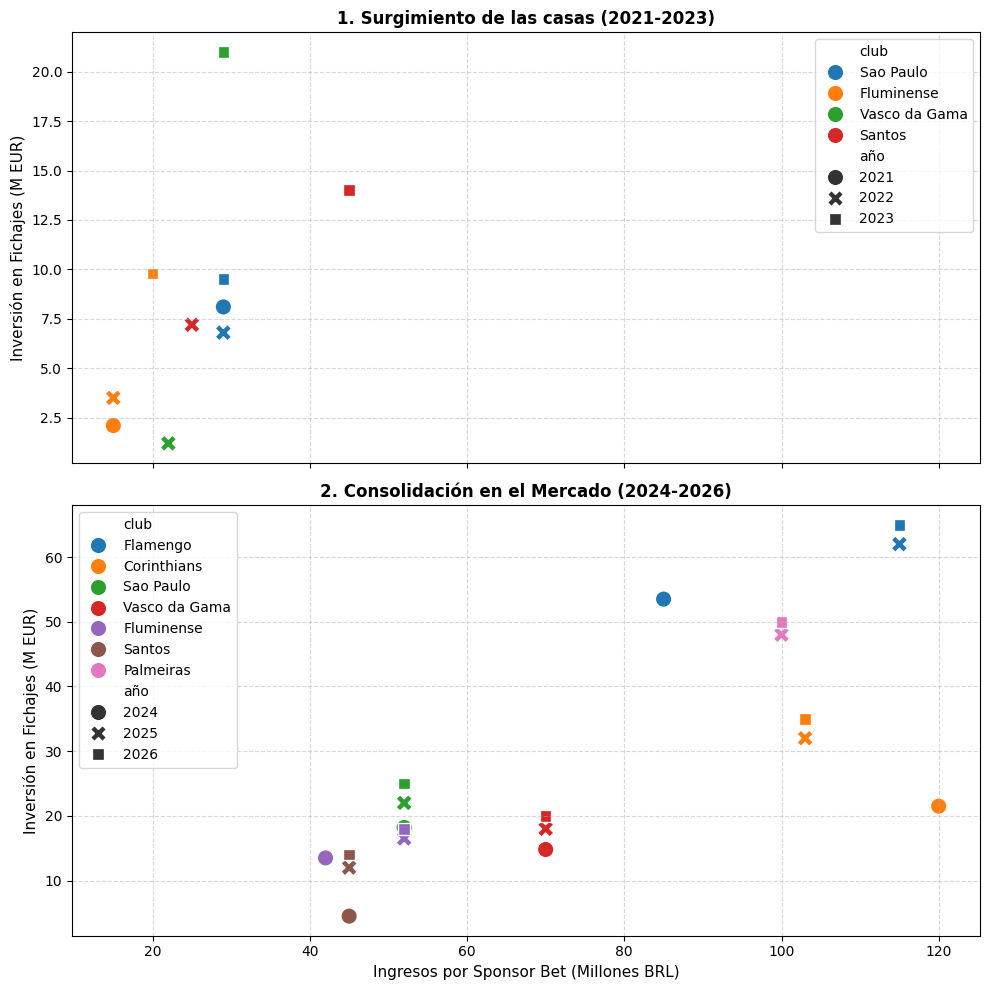

In [45]:
# con un booleano hago una columna que distinga si es un sponsor de apuestas o no

df_brasileirao["es_bet"] = df_brasileirao["patrocinador_master"].str.contains(

    "bet|pix|blaze|esportes", case=False
    )


# divido los periodos

df_periodo1 = df_brasileirao.loc[
    (df_brasileirao["es_bet"] == True) & (df_brasileirao["año"] <= 2023)
]
df_periodo2 = df_brasileirao.loc[
    (df_brasileirao["es_bet"] == True) & (df_brasileirao["año"] >= 2024)
]

# 2. Hacemos la figura con 2 filas x 1 columna compartiendo el eje X
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# Grafico Superior: 2021-2023 (Surgimiento)
sns.scatterplot(
    data=df_periodo1,
    x="ingresos_sponsors_millones_BRL",
    y="gasto_fichajes_millones_EUR",
    hue="club",
    style="año",
    s=140,
    ax=ax1,
)
ax1.set_title(
    "1. Surgimiento de las casas (2021-2023)", fontsize=12, fontweight="bold"
)
ax1.set_ylabel("Inversión en Fichajes (M EUR)", fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.5)

# Grafico Inferior: 2024-2026 (Consolidación)
sns.scatterplot(
    data=df_periodo2,
    x="ingresos_sponsors_millones_BRL",
    y="gasto_fichajes_millones_EUR",
    hue="club",
    style="año",
    s=140,
    ax=ax2,
)
ax2.set_title(
    "2. Consolidación en el Mercado (2024-2026)", fontsize=12, fontweight="bold"
)
ax2.set_xlabel("Ingresos por Sponsor Bet (Millones BRL)", fontsize=11)
ax2.set_ylabel("Inversión en Fichajes (M EUR)", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Como se puede observar, en el grafico del surgimiento los clubes se mantienen casi todos en el primer tercio del eje x, mientras que en el grafico de la consolidacion, el primer tercio pareceria ser el minimo


Esto nos muestra que las casas de apuestas a la vez que inflan la economia de los clubes lo hacen con el mercado de fichajes, mas inyeccion monetaria significa mas gasto en fichajes

In [46]:
# 1. Generamos la columna de ingresos netos(ingreso - gasto)
df_brasileirao["ingresos_netos_transferencias_millones_EUR"] = (
    df_brasileirao["ingresos_ventas_millones_EUR"]
    - df_brasileirao["gasto_fichajes_millones_EUR"]
)

# 2. Mostramos la tabla con las columnas de compras, ventas y el saldo neto resultante
df_brasileirao[
    [
        "club",
        "año",
        "gasto_fichajes_millones_EUR",
        "ingresos_ventas_millones_EUR",
        "ingresos_netos_transferencias_millones_EUR",
    ]
].head(9)

,club,año,gasto_fichajes_millones_EUR,ingresos_ventas_millones_EUR,ingresos_netos_transferencias_millones_EUR
0,Flamengo,2021,14.2,44.0,29.8
1,Palmeiras,2021,7.5,12.5,5.0
2,Corinthians,2021,0.0,18.0,18.0
3,Sao Paulo,2021,8.1,15.2,7.1
4,Vasco da Gama,2021,0.5,6.0,5.5
5,Fluminense,2021,2.1,14.0,11.9
6,Gremio,2021,8.4,21.0,12.6
7,Internacional,2021,4.2,19.5,15.3
8,Santos,2021,6.0,16.0,10.0


Esta columna nos va a permitir analizar

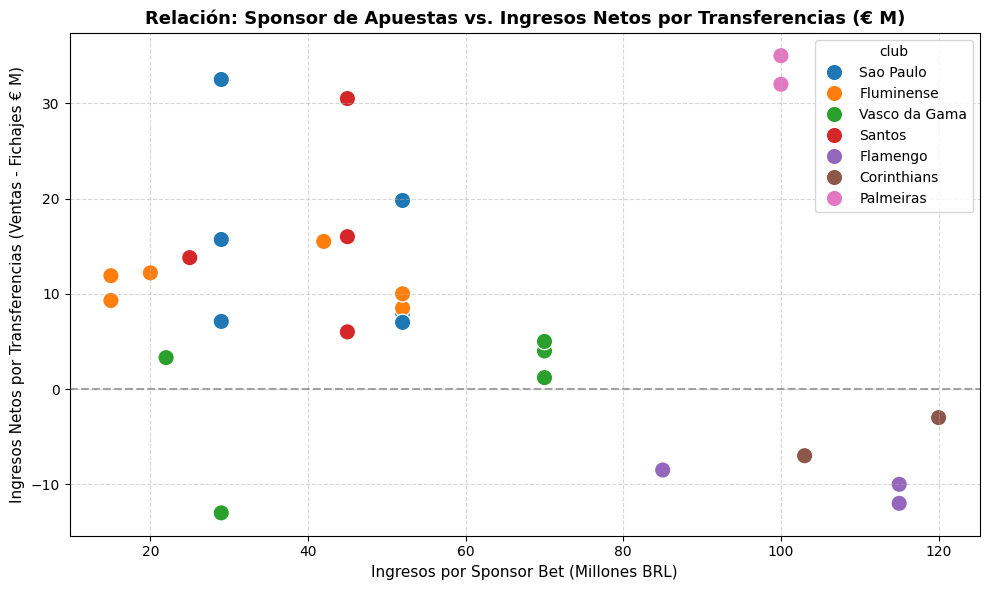

In [47]:
# 1. Gráfico Scatter Plot: Ingresos por Bet vs. Ingresos Netos por Transferencias (€ M)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_brasileirao[df_brasileirao["es_bet"]],
    x="ingresos_sponsors_millones_BRL",
    y="ingresos_netos_transferencias_millones_EUR",
    hue="club",
    s=140,
)

# 2. Línea de referencia horizontal en 0 (puntos positivos = superávit por ventas / negativos = déficit por compras)
plt.axhline(0, color="gray", linestyle="--", alpha=0.7)

# Formato y etiquetas
plt.title(
    "Relación: Sponsor de Apuestas vs. Ingresos Netos por Transferencias (€ M)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Ingresos por Sponsor Bet (Millones BRL)", fontsize=11)
plt.ylabel(
    "Ingresos Netos por Transferencias (Ventas - Fichajes € M)", fontsize=11
)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Podemos señalar que los que mas dinero recibieron por sponsor estan en negativo en ingresos netos por transferencia, lo que quiere decir que al recibir mucho dinero de sponsors se pueden permitir gastar mas de lo que no.
Mientras que los que no reciben tanto de sponsors deben ser cuidadosos con cuanto gastan

In [48]:
resumen_sponsors = (
    df_brasileirao.groupby("es_bet")
    .agg(
        total_sponsors_BRL=("ingresos_sponsors_millones_BRL", "sum"),
        promedio_sponsors_BRL=("ingresos_sponsors_millones_BRL", "mean"),
        total_neto_transferencias_EUR=(
            "ingresos_netos_transferencias_millones_EUR",
            "sum",
        ),
        promedio_neto_transferencias_EUR=(
            "ingresos_netos_transferencias_millones_EUR",
            "mean",
        ),
        total_gasto_fichajes_EUR=("gasto_fichajes_millones_EUR", "sum"),  # <-- Agregamos esta línea
        promedio_puntos=("puntos_obtenidos", "mean"),
        promedio_posicion=("posicion_liga", "mean"),
    )
    .reset_index()
)

# Etiquetar categoría
resumen_sponsors["categoria"] = resumen_sponsors["es_bet"].map(
    {True: "Casas de Apuestas", False: "Sponsors Tradicionales"}
)

display(resumen_sponsors)

,es_bet,total_sponsors_BRL,promedio_sponsors_BRL,total_neto_transferencias_EUR,promedio_neto_transferencias_EUR,total_gasto_fichajes_EUR,promedio_puntos,promedio_posicion,categoria
0,False,759.0,31.625,285.2,11.883333,279.5,60.875000,6.045455,Sponsors Tradicionales
1,True,1746.0,58.200,259.8,8.660000,646.7,56.566667,8.321429,Casas de Apuestas


/tmp/ipykernel_2743/1485065012.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_2743/1485065012.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


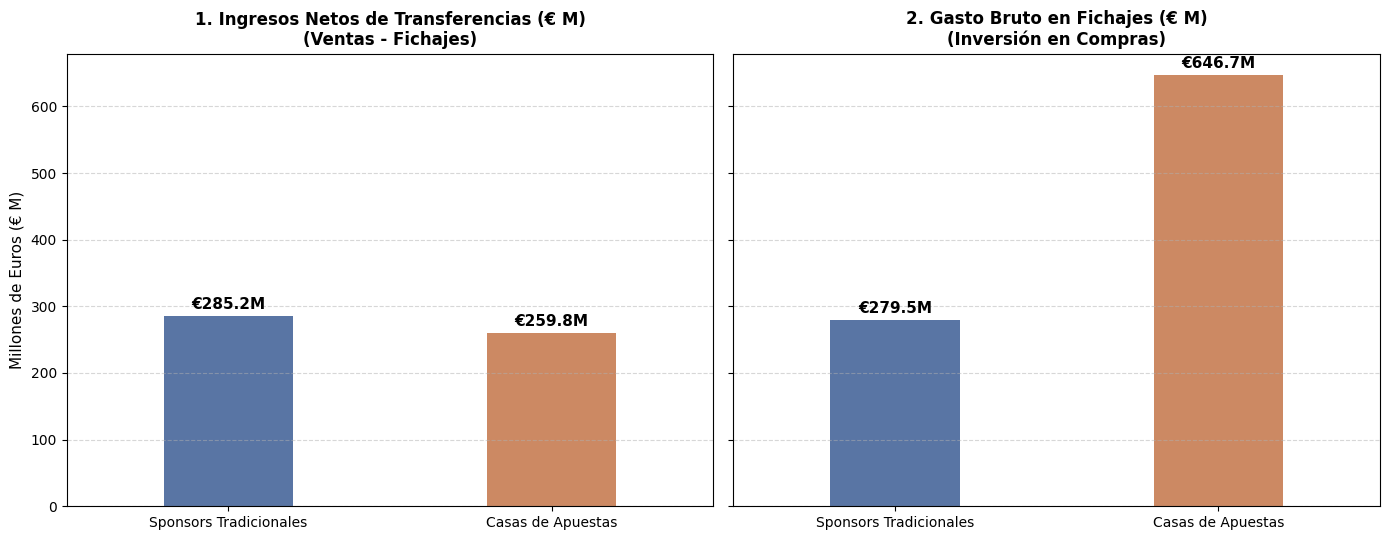

In [49]:
# Creamos 2 subgráficos en una misma figura compartiendo el eje Y (sharey=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

# Subgráfico 1: Ingresos Netos de Transferencias (Ventas - Fichajes)
sns.barplot(
    data=resumen_sponsors,
    x="categoria",
    y="total_neto_transferencias_EUR",
    palette=["#4C72B0", "#DD8452"],
    width=0.4,
    ax=ax1,
)
ax1.set_title(
    "1. Ingresos Netos de Transferencias (€ M)\n(Ventas - Fichajes)",
    fontsize=12,
    fontweight="bold",
)
ax1.set_ylabel("Millones de Euros (€ M)", fontsize=11)
ax1.set_xlabel("")
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# Etiquetas con montos sobre las barras
for bar in ax1.patches:
    ax1.annotate(
        f"€{bar.get_height():.1f}M",
        (bar.get_x() + bar.get_width() / 2.0, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        xytext=(0, 3),
        textcoords="offset points",
    )

# Subgráfico 2: Gasto Bruto en Fichajes (Inversión en Compras)
sns.barplot(
    data=resumen_sponsors,
    x="categoria",
    y="total_gasto_fichajes_EUR",
    palette=["#4C72B0", "#DD8452"],
    width=0.4,
    ax=ax2,
)
ax2.set_title(
    "2. Gasto Bruto en Fichajes (€ M)\n(Inversión en Compras)",
    fontsize=12,
    fontweight="bold",
)
ax2.set_ylabel("")
ax2.set_xlabel("")
ax2.grid(axis="y", linestyle="--", alpha=0.5)

# Etiquetas con montos sobre las barras
for bar in ax2.patches:
    ax2.annotate(
        f"€{bar.get_height():.1f}M",
        (bar.get_x() + bar.get_width() / 2.0, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        xytext=(0, 3),
        textcoords="offset points",
    )

plt.tight_layout()
plt.show()

Confirmamos nuestras sospechas sobre lo anteriormente dicho, los clubes que reciben sponsoreo de casas de apuestas se permiten gastar mas del doble que los tradicionales, pero el ingreso neto en los mercados es igual entre los dos

/tmp/ipykernel_2743/466360001.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


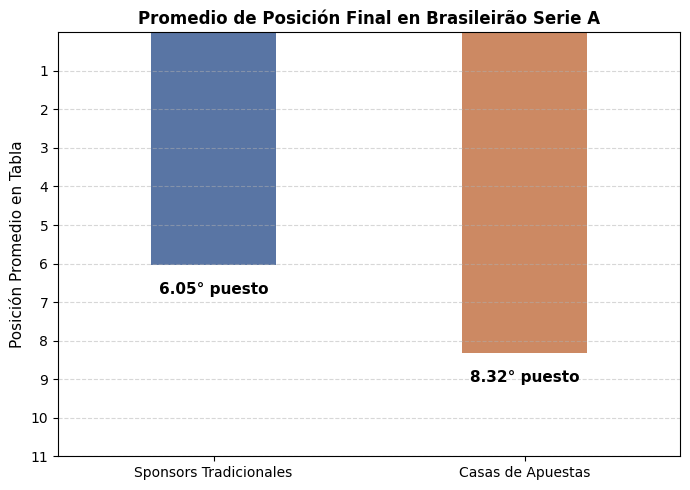

In [50]:
# 1. Filtrar las observaciones válidas de Serie A (excluyendo nulos de Serie B)
df_valid = df_brasileirao.loc[df_brasileirao["posicion_liga"].notnull()].copy()

# 2. Calcular el promedio de posición por categoría de sponsor
promedios_posicion = (
    df_valid.groupby("es_bet")["posicion_liga"].mean().reset_index()
)
promedios_posicion["categoria"] = promedios_posicion["es_bet"].map(
    {True: "Casas de Apuestas", False: "Sponsors Tradicionales"}
)

# 3. Gráfico de Barras con eje Y invertido y barras flacas (width=0.4)
plt.figure(figsize=(7, 5))
ax = sns.barplot(
    data=promedios_posicion,
    x="categoria",
    y="posicion_liga",
    palette=["#4C72B0", "#DD8452"],
    width=0.4,
)

# Invertir el eje Y (para que la posición 1° quede arriba)
plt.gca().invert_yaxis()
plt.yticks(range(1, 12))

plt.title(
    "Promedio de Posición Final en Brasileirão Serie A",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("")
plt.ylabel("Posición Promedio en Tabla", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Anotar valores numéricos exactos sobre las barras
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}° puesto",
        (bar.get_x() + bar.get_width() / 2.0, height),
        ha="center",
        va="top",
        fontsize=11,
        fontweight="bold",
        xytext=(0, -12),
        textcoords="offset points",
    )

plt.tight_layout()
plt.show()

CONCLUSION

con el analisis realizado y la informacion que tenemos la respuesta que se nos permite dar a la pregunta es: **aunque existe una correlación positiva fuerte ( r=0.78 ) entre los ingresos por patrocinios de casas de apuestas y el presupuesto gastado en la compra  de futbolistas, esto no se traduce de forma automática en una ventaja o supremacía deportiva en la tabla de posiciones**

Lo que se puede ver en el ultimo grafico mostrado es que el futbol sigue siendo futbol y aunque hay una importancia en cuanto dinero entra de sponsors, hay que darle una mayor importancia al proyecto futbolistico bien encaminado
